# Этап 1. Ответы модели и её скрытые состояния (локальный запуск)

Этот ноутбук запускается на локальном компьютере с GPU. Убедитесь, что:
- создано виртуальное окружение и установлены зависимости (`pip install -r requirements.txt`);
- CUDA / ROCm видны PyTorch (`torch.cuda.is_available()`);
- RuBQ 2.0 скачан в `data/raw/` и подготовлен `data/questions.jsonl` (`python -m hprobe.data`).

Все результаты пишутся в `outputs/` внутри репозитория. Если прогон прервётся, просто перезапустите ячейку — `generate.py` продолжит с места остановки.

In [3]:
import os
import sys
import subprocess
import torch
from pathlib import Path

# Путь к корню репозитория (папка, в которой лежит notebooks/)
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO / 'src'))

print('Репозиторий:', REPO.resolve())
print('GPU доступна:', torch.cuda.is_available())
if torch.cuda.is_available():
    !nvidia-smi --query-gpu=name,memory.total --format=csv

Репозиторий: /home/aleks/hallucination-probe
GPU доступна: True
name, memory.total [MiB]
NVIDIA GeForce GTX 1070, 8192 MiB


## 0. Подготовка данных (один раз, CPU)

In [ ]:
# Если data/questions.jsonl ещё не создан, раскомментируйте и запустите:
# !PYTHONPATH=src python -m hprobe.data

## 1. Быстрая проверка на 32 вопросах (1–2 минуты)

In [3]:
SMOKE = REPO / 'outputs' / 'smoke'
subprocess.run([
    sys.executable, '-m', 'hprobe.generate',
    '--model', 'Qwen/Qwen2.5-0.5B-Instruct',
    '--lang', 'ru',
    '--limit', '32',
    '--out', str(SMOKE),
    '--batch-size', '8',
], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)

subprocess.run([
    sys.executable, '-m', 'hprobe.label',
    '--run', str(SMOKE),
], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)

import pandas as pd
pd.read_csv(SMOKE / 'labels.csv')[['question', 'answer', 'gold', 'correct', 'consistency']].head(15)

Вопросов: 32, уже готово: 32, осталось: 0


ru: 0it [00:00, ?it/s]


hidden.npy: 32 × (25, 896) → /home/aleks/hallucination-probe/outputs/smoke
/home/aleks/hallucination-probe/outputs/smoke: 32 ответов, верных 3.1%, отказов 0.0%
            mean  size
domain                
culture    0.000     8
geography  0.077    13
history    0.000     1
other      0.000     6
people     0.000     3
sport      0.000     1


,question,answer,gold,correct,consistency
0,Кто написал роман «Хижина дяди Тома»?,Андрей Бородов,Гарриет Бичер-Стоу | Стоу Гарриет Бичер | Биче...,0,0.0
1,Кто автор пьесы «Ромео и Джульетта»?,Английский писатель Пьер Гарсии Бернардес,"Уильям Шекспир | Шекспир, Уильям | Вильям Шекс...",0,0.0
2,Как называется столица Румынии?,Sofia,Бухарест | Букурешти | Paris of the East | Buc...,0,0.2
3,Какой стране принадлежит знаменитый остров Пасхи?,Италия,Чили | Республика Чили | Chile | República de ...,0,0.2
4,На каком инструменте играл Джимми Хендрикс?,Баскетбол,гитара | Семиструнная гитара | Шестиструнная г...,0,0.0
5,Какой стране принадлежит остров Таити?,Филиппиной,Франция | ФР | France | Французская Республика...,0,0.0
6,С какой музыкальной группой неразрывно связано...,Джимми Джаггер,The Rolling Stones | Роллинг Стоунс | Роллинг ...,0,0.0
7,Кто создал Зимний дворец в Санкт-Петербурге?,Иван Грозный,Франческо Растрелли | Франческо Расстрелли | Б...,0,0.0
8,"Кто режиссер фильма ""Бриллиантовая рука""?",Илья Кузнецов,Леонид Иович Гайдай | Леони́д И́ович Гайда́й |...,0,0.0
9,Какой стране принадлежат Канарские острова?,Испания,Испания | Королевство Испания | Эспанья | 🇪🇸 |...,1,0.0


## 2. Основные прогоны

Порядок важен: сначала главная модель (1.5B) на обоих языках, затем 0.5B и 3B для эксперимента с размером модели. Ориентировочно 15–30 минут на прогон 1.5B на GPU с 16 ГБ. Если не хватает памяти, уменьшите `--batch-size`.

In [ ]:
OUT = REPO / 'outputs'
RUNS = [
    ('Qwen/Qwen2.5-1.5B-Instruct', 'qwen2.5-1.5b', 16),
    ('Qwen/Qwen2.5-0.5B-Instruct', 'qwen2.5-0.5b', 32),
    ('Qwen/Qwen2.5-3B-Instruct',   'qwen2.5-3b',   8),
]

for model, short, bs in RUNS:
    for lang in ['ru', 'en']:
        run_out = OUT / short / lang
        print(f'\n=== {model} / {lang} ===')
        subprocess.run([
            sys.executable, '-m', 'hprobe.generate',
            '--model', model,
            '--lang', lang,
            '--out', str(run_out),
            '--batch-size', str(bs),
        ], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)
        subprocess.run([
            sys.executable, '-m', 'hprobe.label',
            '--run', str(run_out),
        ], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)


=== Qwen/Qwen2.5-1.5B-Instruct / ru ===
Вопросов: 2327, уже готово: 2327, осталось: 0


ru: 0it [00:00, ?it/s]


hidden.npy: 2327 × (29, 1536) → /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru
/home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru: 2327 ответов, верных 21.5%, отказов 0.2%
            mean  size
domain                
culture    0.109   470
geography  0.205   522
history    0.365   474
other      0.180   406
people     0.194   315
science    0.351    57
sport      0.181    83
Для ручной проверки: /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru/manual_check.csv

=== Qwen/Qwen2.5-1.5B-Instruct / en ===
Вопросов: 2327, уже готово: 0, осталось: 2327


en:   0%|          | 0/146 [00:00<?, ?it/s]Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)
From v4.47 onwards, when a model cache is to be returned, `generate` will return a `Cache` instance instead by default (as opposed to the legacy tuple of tuples format). If you want to keep returning the legacy format, please set `return_legacy_cache=True`.
en: 100%|██████████| 146/146 [58:31<00:00, 24.05s/it]


hidden.npy: 2327 × (29, 1536) → /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/en
/home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/en: 2327 ответов, верных 42.0%, отказов 0.0%
            mean  size
domain                
culture    0.270   470
geography  0.561   522
history    0.462   474
other      0.431   406
people     0.324   315
science    0.614    57
sport      0.325    83
Для ручной проверки: /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/en/manual_check.csv

=== Qwen/Qwen2.5-0.5B-Instruct / ru ===
Вопросов: 2327, уже готово: 0, осталось: 2327


ru:   0%|          | 0/73 [00:00<?, ?it/s]Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)
From v4.47 onwards, when a model cache is to be returned, `generate` will return a `Cache` instance instead by default (as opposed to the legacy tuple of tuples format). If you want to keep returning the legacy format, please set `return_legacy_cache=True`.
ru: 100%|██████████| 73/73 [54:56<00:00, 45.16s/it]


hidden.npy: 2327 × (25, 896) → /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/ru
/home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/ru: 2327 ответов, верных 10.1%, отказов 0.0%
            mean  size
domain                
culture    0.049   470
geography  0.071   522
history    0.192   474
other      0.081   406
people     0.133   315
science    0.088    57
sport      0.036    83
Для ручной проверки: /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/ru/manual_check.csv

=== Qwen/Qwen2.5-0.5B-Instruct / en ===
Вопросов: 2327, уже готово: 0, осталось: 2327


en:   0%|          | 0/73 [00:00<?, ?it/s]Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)
From v4.47 onwards, when a model cache is to be returned, `generate` will return a `Cache` instance instead by default (as opposed to the legacy tuple of tuples format). If you want to keep returning the legacy format, please set `return_legacy_cache=True`.
en: 100%|██████████| 73/73 [38:50<00:00, 31.93s/it]


hidden.npy: 2327 × (25, 896) → /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/en
/home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/en: 2327 ответов, верных 27.7%, отказов 0.0%
            mean  size
domain                
culture    0.157   470
geography  0.402   522
history    0.325   474
other      0.266   406
people     0.225   315
science    0.298    57
sport      0.133    83
Для ручной проверки: /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/en/manual_check.csv

=== Qwen/Qwen2.5-3B-Instruct / ru ===
Вопросов: 2327, уже готово: 0, осталось: 2327


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

## 3. Ручная проверка разметки

В папке каждого прогона появился `manual_check.csv` (100 случайных ответов). Для главного прогона `qwen2.5-1.5b/ru` откройте файл в Excel/LibreOffice, в столбце `human` поставьте 1, если ответ модели верный, и 0, если неверный. Сохраните как CSV на то же место и запустите ячейку ниже: получится точность автоматической разметки — это число пойдёт в тезисы.

In [4]:
OUT = REPO / 'outputs'
subprocess.run([
    sys.executable, '-m', 'hprobe.label',
    '--run', str(OUT / 'qwen2.5-1.5b' / 'ru'),
    '--check',
], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)

Проверено вручную: 0, совпадение с автоматической разметкой: nan%
Empty DataFrame
Columns: [question, answer, gold, correct, human]
Index: []


CompletedProcess(args=['/home/aleks/hallucination-probe/.venv/bin/python', '-m', 'hprobe.label', '--run', '/home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru', '--check'], returncode=0)

## 4. Первые результаты: пробы по слоям

Для каждого прогона обучаются пробы по всем слоям и сравниваются с базовыми методами. GPU не нужен. График `probe/layers.png` и таблица `probe/summary.csv` сохраняются в папке прогона.


--- /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/en ---
/home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/en: 2327 вопросов, доля ошибок 72.3%, слоёв 25
 base_error_rate                          method  uses_answer  test_auc  ci_low  ci_high  test_pr_auc
           0.721      Проба, слой 22 (до ответа)        False     0.816   0.764    0.865        0.913
           0.721 Самосогласованность (5 сэмплов)         True     0.816   0.763    0.860        0.893
           0.721                Средняя энтропия         True     0.808   0.748    0.862        0.899
           0.721            Энтропия 1-го токена         True     0.806   0.751    0.854        0.910
           0.721           Средний log p токенов         True     0.797   0.738    0.849        0.894
           0.721        Минимальный log p токена         True     0.784   0.726    0.838        0.894
           0.721         Вероятность 1-го токена         True     0.783   0.727    0.836        0.894


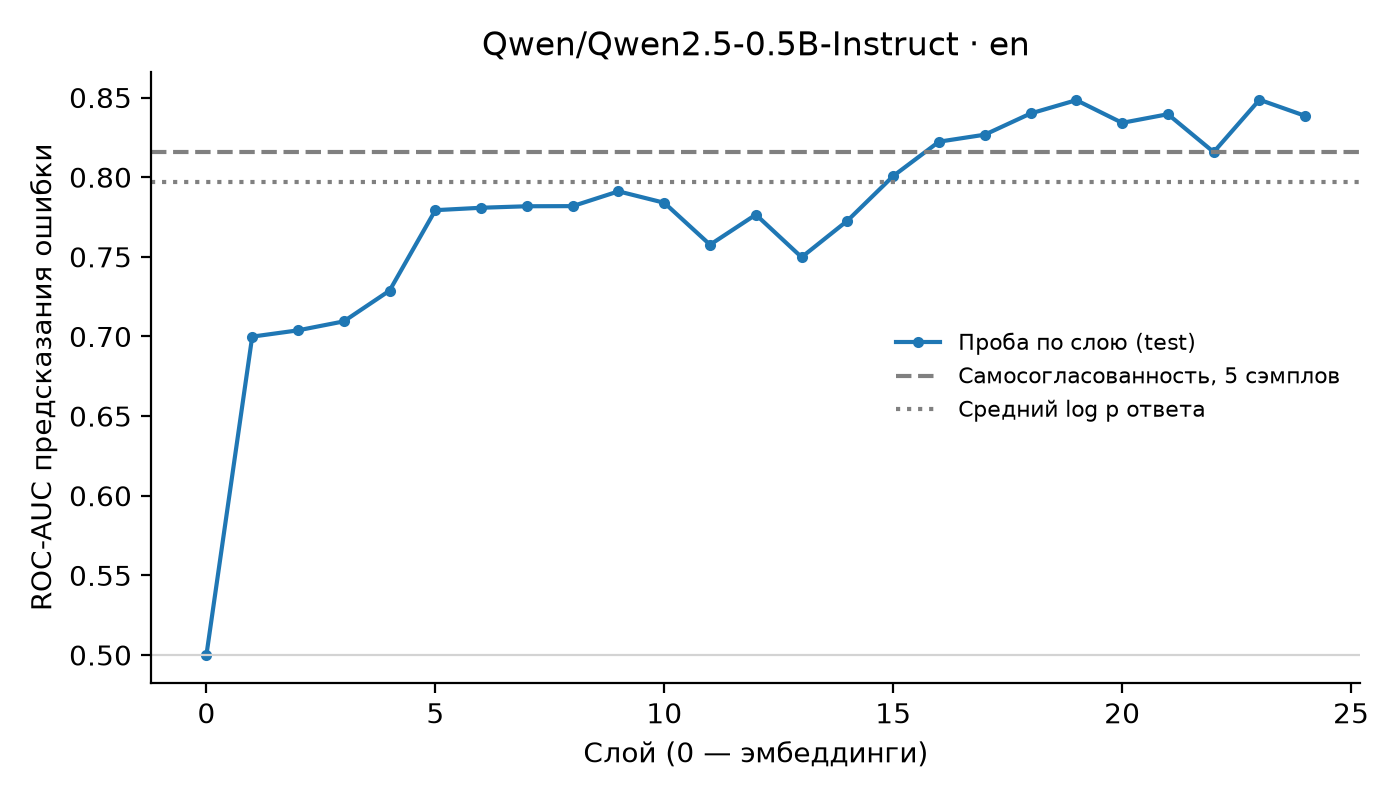


--- /home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/ru ---
/home/aleks/hallucination-probe/outputs/qwen2.5-0.5b/ru: 2327 вопросов, доля ошибок 89.9%, слоёв 25
 base_error_rate                          method  uses_answer  test_auc  ci_low  ci_high  test_pr_auc
           0.894                Средняя энтропия         True     0.778   0.702    0.850        0.965
           0.894        Минимальный log p токена         True     0.767   0.666    0.852        0.951
           0.894           Средний log p токенов         True     0.765   0.694    0.837        0.962
           0.894         Вероятность 1-го токена         True     0.762   0.671    0.845        0.956
           0.894      Проба, слой 24 (до ответа)        False     0.683   0.570    0.794        0.922
           0.894 Самосогласованность (5 сэмплов)         True     0.682   0.594    0.767        0.931
           0.894            Энтропия 1-го токена         True     0.673   0.551    0.782        0.924


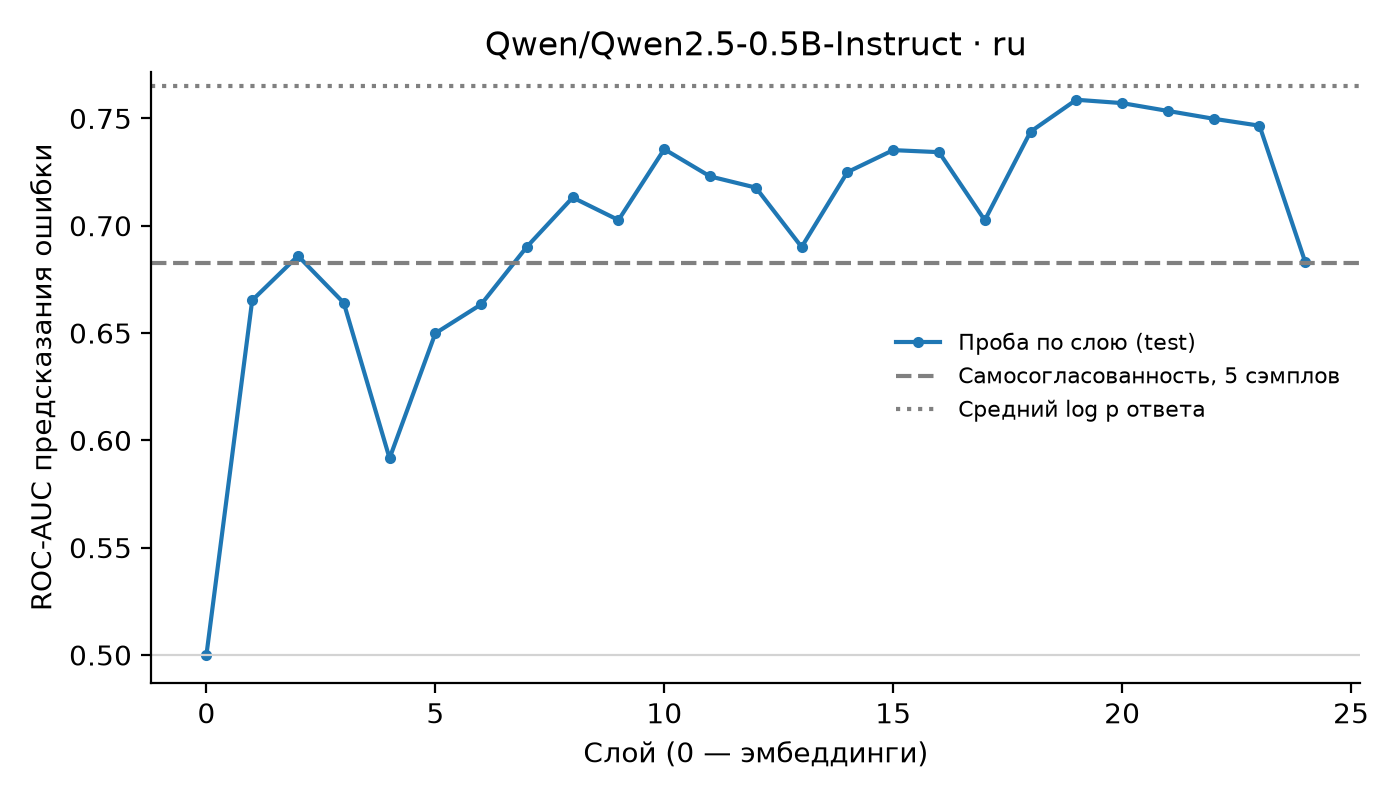


--- /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/en ---
/home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/en: 2327 вопросов, доля ошибок 58.0%, слоёв 29
 base_error_rate                          method  uses_answer  test_auc  ci_low  ci_high  test_pr_auc
           0.606                Средняя энтропия         True     0.865   0.826    0.903        0.905
           0.606            Энтропия 1-го токена         True     0.855   0.810    0.897        0.889
           0.606           Средний log p токенов         True     0.843   0.800    0.881        0.883
           0.606         Вероятность 1-го токена         True     0.824   0.774    0.869        0.861
           0.606        Минимальный log p токена         True     0.818   0.768    0.862        0.862
           0.606      Проба, слой 16 (до ответа)        False     0.816   0.772    0.858        0.873
           0.606 Самосогласованность (5 сэмплов)         True     0.816   0.768    0.859        0.827


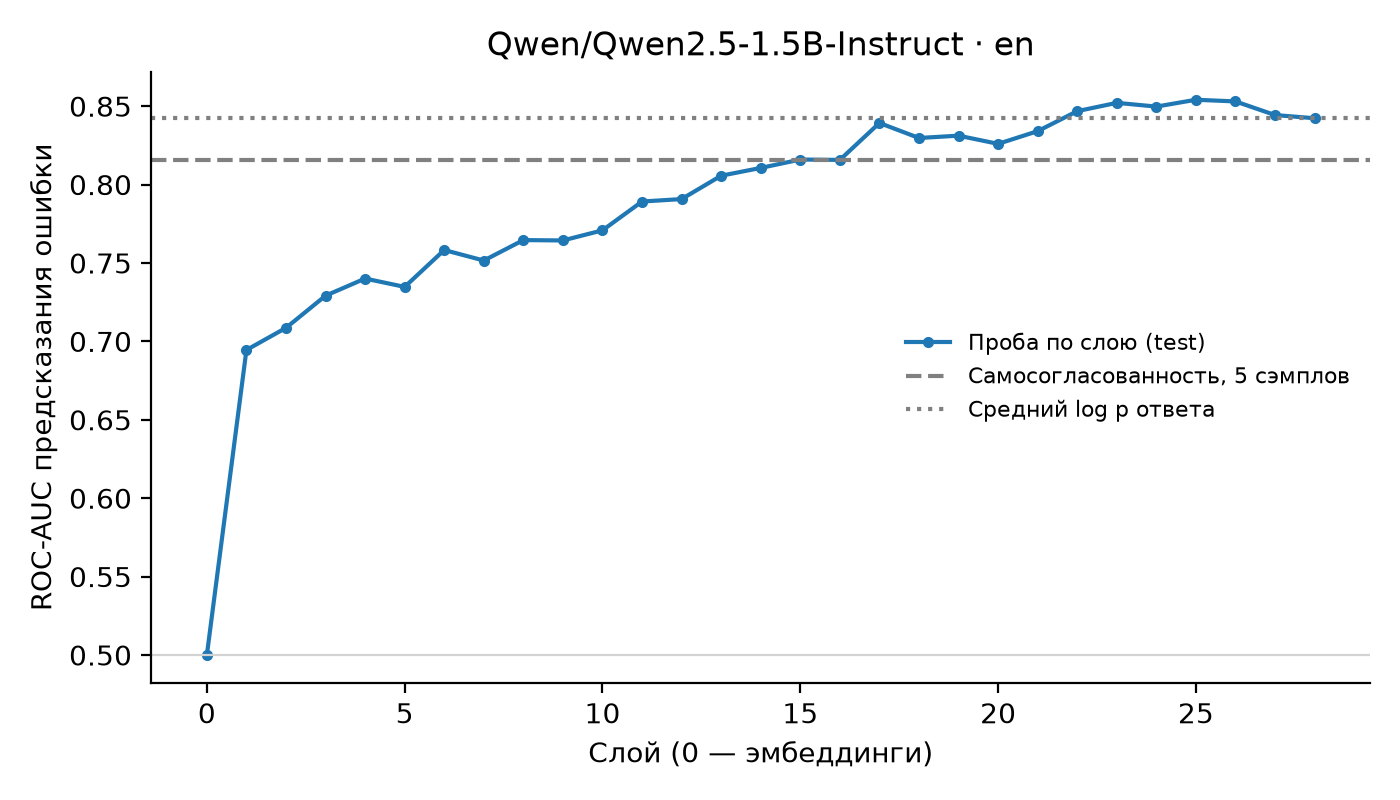


--- /home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru ---
/home/aleks/hallucination-probe/outputs/qwen2.5-1.5b/ru: 2327 вопросов, доля ошибок 78.5%, слоёв 29
 base_error_rate                          method  uses_answer  test_auc  ci_low  ci_high  test_pr_auc
           0.802                Средняя энтропия         True     0.871   0.820    0.914        0.955
           0.802           Средний log p токенов         True     0.863   0.813    0.907        0.958
           0.802        Минимальный log p токена         True     0.836   0.780    0.887        0.949
           0.802      Проба, слой 18 (до ответа)        False     0.827   0.771    0.880        0.947
           0.802            Энтропия 1-го токена         True     0.823   0.761    0.879        0.939
           0.802         Вероятность 1-го токена         True     0.818   0.756    0.873        0.938
           0.802 Самосогласованность (5 сэмплов)         True     0.812   0.750    0.867        0.924


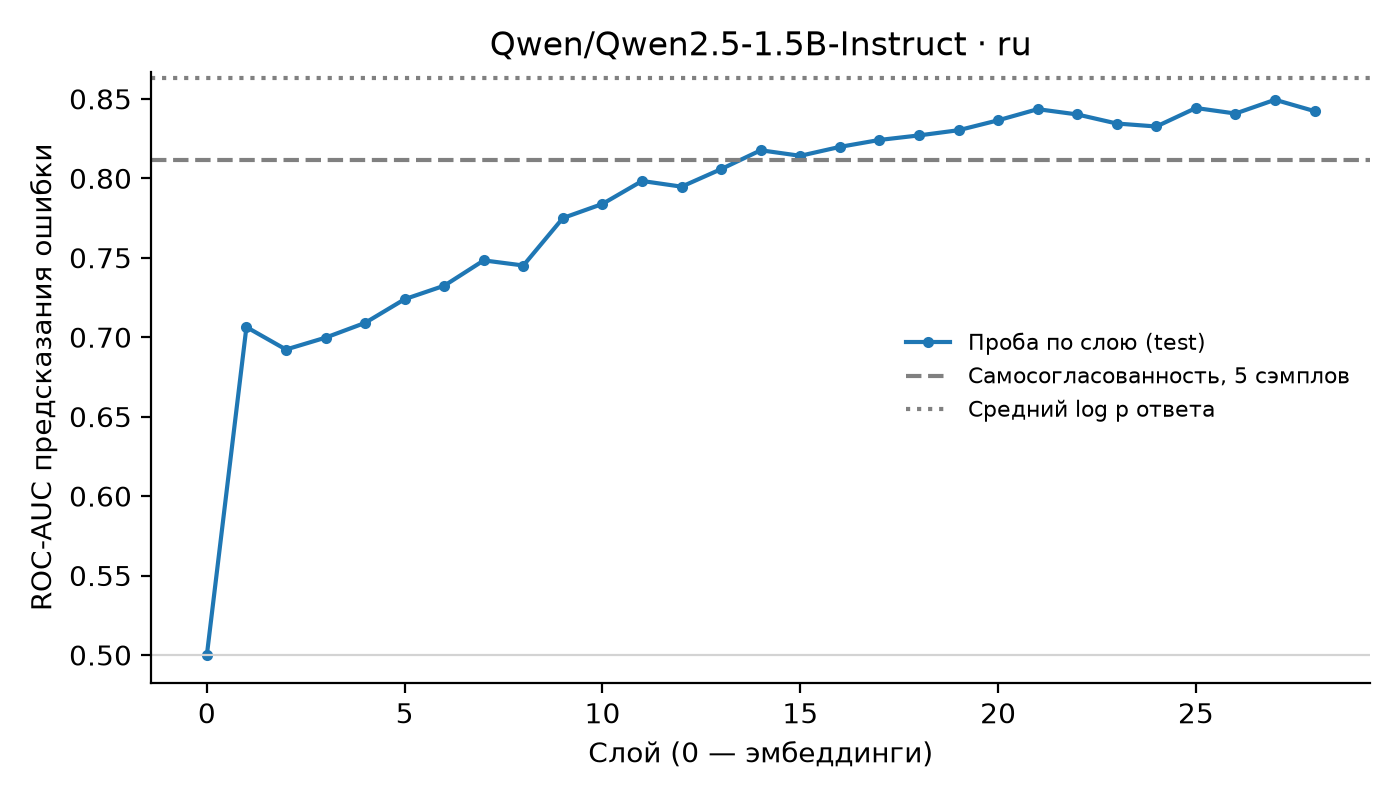


--- /home/aleks/hallucination-probe/outputs/qwen2.5-3b/ru ---


Traceback (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/home/aleks/hallucination-probe/src/hprobe/probes.py", line 166, in <module>
    main()
  File "/home/aleks/hallucination-probe/src/hprobe/probes.py", line 153, in main
    df, hidden = load_run(run)
                 ^^^^^^^^^^^^^
  File "/home/aleks/hallucination-probe/src/hprobe/probes.py", line 39, in load_run
    labels = pd.read_csv(run / "labels.csv")
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/aleks/hallucination-probe/.venv/lib/python3.11/site-packages/pandas/io/parsers/readers.py", line 1866, in read_csv
    return _read(filepath_or_buffer, kwds)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/aleks/hallucination-probe/.venv/lib/python3.11/site-packages/pandas/io/parsers/readers.py", line 423, in _read
    parser = TextFileReader(filepath_or_buffer, **kwds)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

CalledProcessError: Command '['/home/aleks/hallucination-probe/.venv/bin/python', '-m', 'hprobe.probes', '--run', '/home/aleks/hallucination-probe/outputs/qwen2.5-3b/ru']' returned non-zero exit status 1.

In [4]:
from IPython.display import Image, display
import subprocess

OUT = REPO / 'outputs'

for run in sorted(OUT.glob('*/*')):
    if not (run / 'hidden.npy').exists():
        continue
    print(f'\n--- {run} ---')
    subprocess.run([
        sys.executable, '-m', 'hprobe.probes',
        '--run', str(run),
    ], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)
    display(Image(filename=run / 'probe' / 'layers.png', width=600))

## 5. Адаптивный поиск (опционально, GPU)

Для лучшей модели/языка строится кривая «точность vs доля вопросов с поиском». Абзацы берутся из RuBQ.

In [5]:
subprocess.run([
    sys.executable, '-m', 'hprobe.search',
    '--run', str(OUT / 'qwen2.5-1.5b' / 'ru'),
    '--model', 'Qwen/Qwen2.5-1.5B-Instruct',
    '--lang', 'ru',
], cwd=REPO, env={**os.environ, 'PYTHONPATH': 'src'}, check=True)

display(Image(filename=OUT / 'qwen2.5-1.5b' / 'ru' / 'search' / 'curve.png', width=500))

search:   0%|          | 0/562 [00:00<?, ?it/s]/home/aleks/hallucination-probe/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:601: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/aleks/hallucination-probe/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:606: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/home/aleks/hallucination-probe/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:623: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset

KeyboardInterrupt: 